# Part 4 | Spike waveforms & spatial footprints

Each neuron has a characteristic spike **shape**. Averaging the signal around
all of a unit's spikes reveals its **mean waveform**. A spike is not seen on one
electrode only — it spreads across **neighbouring electrodes** with decreasing
amplitude. Plotting the mean waveform at each electrode's position gives the
neuron's **footprint**, a spatial fingerprint.

## Goal

Characterise a neuron by the shape of its spike and how it spreads over the electrodes.

By the end of this part you can:
- compute a unit's mean waveform and its amplitude
- build its spatial footprint on the neighbouring electrodes
- measure the spike width (trough-to-peak)

> **How the exercises work.** You will meet three kinds of boxes:
> - **✎ Your turn** — one line of code to complete: look for `# TODO` and the
>   obviously-wrong placeholder (e.g. `0.0`). The explanation or worked example
>   just above it shows what you need, and a **check** prints `[OK]` when you
>   got it, or a hint if not.
> - **💬 Discuss:** — a question to discuss with your partner. No code, no check.
> - **🔧 Try it:** — an optional experiment: change a value, re-run, and see what
>   happens. Set it back afterwards.
>
> The full answers live in `mea_helpers.py` if you ever want to peek.

In [1]:
# ========================= YOUR SETTINGS ==============================
GROUP_ID  = 1            # your group number (data exists for groups 1 and 2)
DRUG      = "A"          # config / drug label:  group 1 -> A,B,C,D   group 2 -> A,B
CONDITION = "Baseline"   # "Baseline" or "Drug"

# Path to YOUR group's manifest: the recordings.toml in your group folder on
# the bs-dfs share (the exact path is handed out with the practical), e.g.
#   r"Z:\BEL\Practicals_2026\Group_01\recordings.toml"
MANIFEST  = r"PASTE-THE-PATH-TO-YOUR-recordings.toml"

# The manifest stores full paths to the data, so DATA_ROOT is not used here.
# (Leave as ".": it only matters if your manifest uses relative paths.)
DATA_ROOT = "."
# ======================================================================

import sys; sys.path.append("..")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import mea_helpers as mea

manifest = mea.load_manifest(MANIFEST)
row = mea.find_recording(manifest, GROUP_ID, DRUG, CONDITION)
print("Selected recording:"); print(row)

Selected recording:
UID                        G05_A_Baseline
GroupID                                 5
Chip                               maxtwo
Drug                                    A
Conditions                       Baseline
Well                                    0
raw_files       raw/G05_A_Baseline.raw.h5
sorted_files        sorted/G05_A_Baseline
Name: 0, dtype: object


## 1. Load the recording and the curated units

Same curation as in Part 3. We pick a curated unit that is seen on many
electrodes, so its footprint is easy to see.

In [2]:
recording = mea.open_recording(row, data_root=DATA_ROOT)
fs = recording.get_sampling_frequency()
duration = recording.get_num_frames() / fs
rec_f = mea.bandpass_recording(recording)       # filtered view

sorting = mea.load_sorting(row, data_root=DATA_ROOT)
feats = mea.unit_features(mea.sorting_to_spikes(sorting), duration, sorting=sorting)
clean = mea.curate_units(feats)

# Try other units too: uid = clean.index[k]
uid = mea.pick_footprint_unit(sorting, unit_ids=clean.index)
spike_times = sorting.get_unit_spike_train(unit_id=uid) / fs
print(f"{len(clean)} curated units; using unit {uid} ({len(spike_times)} spikes)")

225 curated units; using unit 38 (859 spikes)


## 2. Mean waveform of a single unit

We read short cutouts around (up to) 100 of the unit's spikes from the filtered
recording, average them, and keep the electrode where the spike is largest —
the **peak channel**.

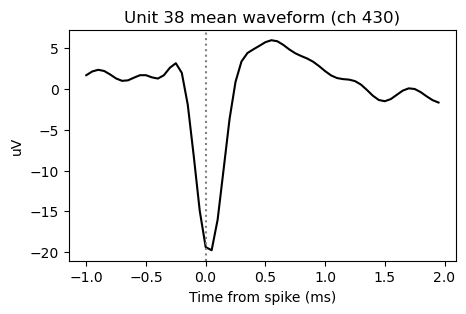

In [3]:
t_ms, wf, peak_ch = mea.unit_mean_waveform(rec_f, sorting, uid, max_spikes=100)

plt.figure(figsize=(5, 3))
plt.plot(t_ms, wf, "k")
plt.axvline(0, color="gray", ls=":"); plt.xlabel("Time from spike (ms)")
plt.ylabel("uV"); plt.title(f"Unit {uid} mean waveform (ch {peak_ch})"); plt.show()

### ✎ Your turn — the spike amplitude

`wf` is the unit's mean waveform from the plot above: one value (µV) per
sample, and `t_ms` holds the time of each sample. The **amplitude** is the
waveform's value at its **trough**, the most negative point. Spikes point
downward here, so the amplitude is a **negative** number.

Two steps:
1. find the *index* of the trough — `np.argmin(wf)` returns the index of the
   smallest value;
2. read the waveform at that index (already done for you below).

In [4]:
# TODO: replace the 0 with the index of the trough (the most negative point of wf).
trough_index = 0

amplitude = wf[trough_index]                       # the waveform's value there
print(f"trough at {t_ms[trough_index]:.2f} ms, amplitude = {amplitude:.1f} uV")

mea.check(amplitude, mea.waveform_metrics(wf, fs)["amplitude_uv"],
          hint="trough_index = np.argmin(wf)")

trough at -1.00 ms, amplitude = 1.7 uV
[X] not quite yet.
   hint: trough_index = np.argmin(wf)
   you got: 1.6972039755433799
   expected ~ -19.78458619594574


False

## 3. The spatial footprint

Now average the same spikes on **all electrodes within 60 µm** of the peak
channel.

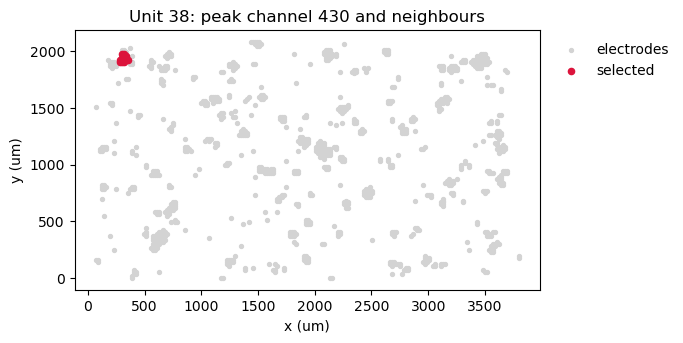

In [5]:
neigh_ids, neigh_locs = mea.neighbouring_channels(recording, peak_ch, radius_um=60)

mea.plot_config_map(recording, highlight=neigh_ids)
plt.title(f"Unit {uid}: peak channel {peak_ch} and neighbours"); plt.show()

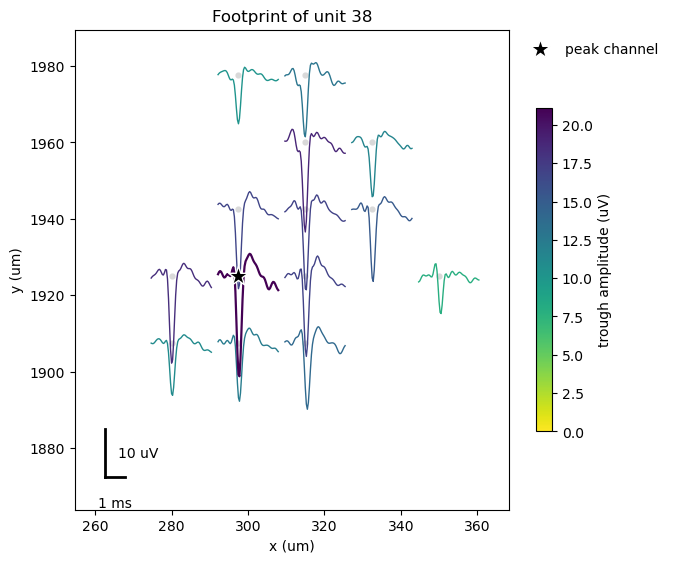

In [6]:
mean_wf, t_ms = mea.extract_footprint(rec_f, spike_times, neigh_ids, max_spikes=100)
mea.plot_footprint(mean_wf, t_ms, neigh_locs)
plt.title(f"Footprint of unit {uid}"); plt.show()

### ✎ Your turn — measure the spike width (trough-to-peak)

A waveform goes down to a **trough**, then back up to a **peak**. The time
between the two, the **trough-to-peak** time, is a classic way to tell cell
types apart (narrow vs broad spikes).

The code below takes the waveform on the peak channel of the footprint
(`wf_peak`) and already finds the trough (`trough`, an index). Your task: find
the index of the **peak after the trough**.

- `wf_peak[trough:]` is the part of the waveform from the trough onward;
- `np.argmax(...)` of that part gives the position of its maximum — counted
  from the trough, so **add `trough`** to get the index in the whole waveform.

The difference between the two indices, divided by the sampling rate `fs`, is
the width (converted to ms for you).

In [7]:
wf_peak = mean_wf[:, int(np.argmin(mean_wf.min(axis=0)))]   # waveform on the peak channel
trough = int(np.argmin(wf_peak))                             # index of the trough

# TODO: replace the 0 with the index of the PEAK that comes AFTER the trough.
peak_after = 0

trough_to_peak_ms = (peak_after - trough) / fs * 1e3
print(f"trough-to-peak = {trough_to_peak_ms:.2f} ms")

mea.check(trough_to_peak_ms, mea.waveform_metrics(wf_peak, fs)["trough_to_peak_ms"],
          tol=0.05, hint="peak_after = trough + np.argmax(wf_peak[trough:])")

trough-to-peak = -1.05 ms
[X] not quite yet.
   hint: peak_after = trough + np.argmax(wf_peak[trough:])
   you got: -1.05
   expected ~ 0.5


False

> **💬 Discuss:** does the amplitude shrink as electrodes get further from the peak channel? What does that tell you about where the neuron sits?